<a href="https://colab.research.google.com/github/vera2005/MLCV_course1/blob/main/Lesson5/Lesson_5_FULL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**0.Ипорты**

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO

**1. Загрузка ResNet**

In [3]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input, decode_predictions

# Загружаем модель с весами, обученными на ImageNet
resnet = ResNet50(weights='imagenet')

print("Форма входа:", resnet.input_shape)
print("Форма выхода:", resnet.output_shape)
print(f"Всего параметров: {resnet.count_params():,}")

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Форма входа: (None, 224, 224, 3)
Форма выхода: (None, 1000)
Всего параметров: 25,636,712


**2.Классификация картинки**

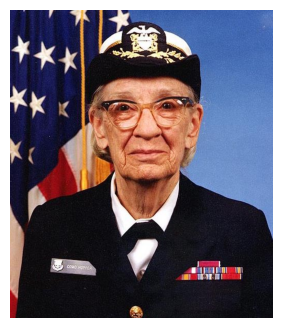

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 думает:
  1. military_uniform: 98.92%
  2. cornet: 0.23%
  3. bearskin: 0.20%
  4. bulletproof_vest: 0.08%
  5. suit: 0.06%


In [4]:
def classify_url(url, model=resnet, top=5):
    # 1. Скачиваем картинку по ссылке
    img = Image.open(BytesIO(requests.get(url).content)).convert('RGB')
    # 2. Показываем её на экране
    plt.figure(figsize=(5, 4))
    plt.imshow(img)
    plt.axis('off')
    plt.show()

    # 3. Готовим картинку для нейросети
    x = img.resize((224, 224))             # Ресайз под вход ResNet
    x = np.array(x)                        # Картинка -> массив чисел
    x = np.expand_dims(x, axis=0)          # Добавляем размерность батча
    x = preprocess_input(x)                # Нормализация (наш "переходник")
    # 4. Отдаем в сеть
    preds = model.predict(x)
    # 5. Переводим числа в слова
    results = decode_predictions(preds, top=top)[0]


    print("ResNet50 думает:")
    for i, (imagenet_id, label, prob) in enumerate(results, 1):
        print(f"  {i}. {label}: {prob * 100:.2f}%")

# Запускаем на классической картинке с Грейс Хоппер (первая леди ВМС США)
classify_url("https://storage.googleapis.com/download.tensorflow.org/example_images/grace_hopper.jpg")

**3.Предсказываем наше изображние**

Загрузите картинку с одним объектом:


Saving dog2.jpg to dog2.jpg


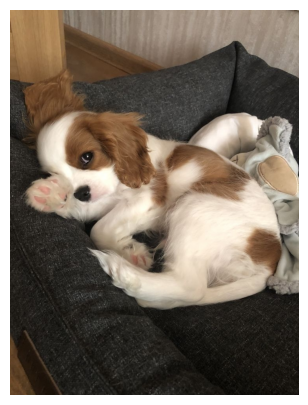


Топ-5, что думает ResNet50:
  1. Blenheim_spaniel: 98.39%
  2. Welsh_springer_spaniel: 0.87%
  3. papillon: 0.30%
  4. English_springer: 0.23%
  5. Japanese_spaniel: 0.10%


In [5]:
from google.colab import files
import io

# 1. Открываем диалоговое окно для загрузки файла
print("Загрузите картинку с одним объектом:")
uploaded = files.upload()

# 2. Берем имя загруженного файла
fn = list(uploaded.keys())[0]

# 3. Открываем картинку
img = Image.open(fn).convert('RGB')
plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.axis('off')
plt.show()

# 4. Готовим картинку (те же шаги, что и с URL)
x = img.resize((224, 224))
x = np.array(x)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

# 5. Отдаем в сеть и расшифровываем
preds = resnet.predict(x, verbose=0)

print("\nТоп-5, что думает ResNet50:")
for i, (imagenet_id, label, prob) in enumerate(decode_predictions(preds, top=5)[0], 1):
    print(f"  {i}. {label}: {prob * 100:.2f}%")

**4. Загружаем датасет для дообучения**

In [7]:
import pathlib

# Ссылка на архив с картинками (содержит 5 папок с цветами)
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

# Скачиваем и распаковываем
data_dir = tf.keras.utils.get_file('flower_photos', origin=url, untar=True)
data_dir = pathlib.Path(data_dir)

if (data_dir / 'flower_photos').exists():
    data_dir = data_dir / 'flower_photos'

# Смотрим, какие классы (папки) есть в датасете
classes = sorted([p.name for p in data_dir.glob('*') if p.is_dir()])
print("Классы:", classes)

# Считаем, сколько картинок в каждом классе
for cls in classes:
    n = len(list((data_dir / cls).glob('*.jpg')))
    print(f"  {cls}: {n} картинок")

Классы: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
  daisy: 633 картинок
  dandelion: 898 картинок
  roses: 641 картинок
  sunflowers: 699 картинок
  tulips: 799 картинок


**5. Отображение картинок из датасета для дообучения**

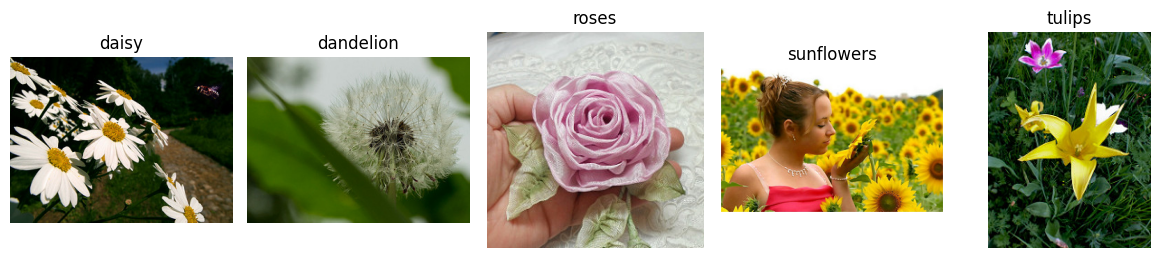

In [8]:
import random

# Создаем холст для 10 картинок (2 ряда по 5 штук)
plt.figure(figsize=(12, 5))

# Проходимся по каждому классу
for i, cls in enumerate(classes):
    # Берем все файлы в папке класса
    files_list = list((data_dir / cls).glob('*.jpg'))

    # Выбираем случайную картинку
    random_img_path = random.choice(files_list)

    # Открываем её
    img = Image.open(random_img_path)

    # Рисуем на холсте (слот i+1, так как индексы начинаются с 1)
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis('off')

# Чтобы картинки не наезжали друг на друга
plt.tight_layout()
plt.show()

**6. ДООБУЧЕНИЕ МОДЕЛИ**

In [9]:
from tensorflow.keras import layers, models

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# 1. Загружаем данные из папок в tf.data (сразу создаем train и val)
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH_SIZE)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH_SIZE)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Классы:", class_names)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Классы: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


Функция нормализации (применяем preprocess_input к каждому батчу)

In [10]:
def preprocess(x, y):
    return preprocess_input(x), y

train_ds = train_ds.map(preprocess).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.map(preprocess).prefetch(tf.data.AUTOTUNE)

Собираем Франкенштейна

In [11]:
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable=False

# Собираем свой пайплайн через Functional API
inputs = layers.Input(shape=(224, 224, 3))
# Аугментация (немного улучшим данные на лету)
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1)(x)

# Пропускаем через замороженную базу
x = base_model(x, training=False)
# Наша новая "голова"
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

# Финальная модель
model = models.Model(inputs, outputs)



94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


**7.Компиляция**

In [12]:
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])


In [13]:
trainable_count = sum([tf.size(w).numpy() for w in model.trainable_weights])
total_count = sum([tf.size(w).numpy() for w in model.weights])
print(f"Обучаемых параметров: {trainable_count:,} из {total_count:,}")

Обучаемых параметров: 10,245 из 23,597,957


**8.Обучение**

In [14]:
history_fe = model.fit(train_ds, validation_data=val_ds, epochs=5)

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 29s 202ms/step - accuracy: 0.7480 - loss: 0.6861 - val_accuracy: 0.8638 - val_loss: 0.4184
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 172ms/step - accuracy: 0.8740 - loss: 0.3546 - val_accuracy: 0.9033 - val_loss: 0.3297
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 194ms/step - accuracy: 0.9022 - loss: 0.2695 - val_accuracy: 0.8856 - val_loss: 0.3843
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 175ms/step - accuracy: 0.9162 - loss: 0.2342 - val_accuracy: 0.8883 - val_loss: 0.3680
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 177ms/step - accuracy: 0.9271 - loss: 0.2146 - val_accuracy: 0.9196 - val_loss: 0.3042


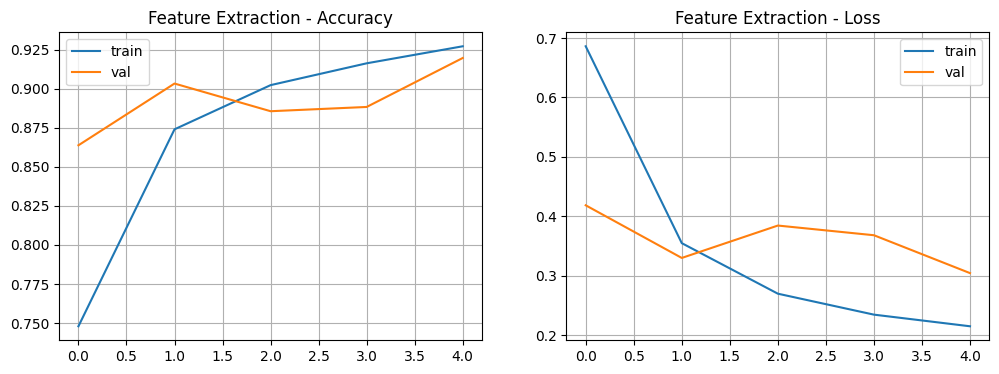

In [15]:
# Строим графики
def plot_history(history, title="Модель"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # График точности
    ax1.plot(history.history['accuracy'], label='train')
    ax1.plot(history.history['val_accuracy'], label='val')
    ax1.set_title(f'{title} - Accuracy')
    ax1.legend(); ax1.grid(True)

    # График ошибки
    ax2.plot(history.history['loss'], label='train')
    ax2.plot(history.history['val_loss'], label='val')
    ax2.set_title(f'{title} - Loss')
    ax2.legend(); ax2.grid(True)

    plt.show()

plot_history(history_fe, "Feature Extraction")

Добавляем Fine-tuning

Epoch 1/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 35s 246ms/step - accuracy: 0.9169 - loss: 0.2364 - val_accuracy: 0.9114 - val_loss: 0.2801
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 221ms/step - accuracy: 0.9418 - loss: 0.1746 - val_accuracy: 0.9155 - val_loss: 0.2696
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 21s 224ms/step - accuracy: 0.9547 - loss: 0.1376 - val_accuracy: 0.9237 - val_loss: 0.2554


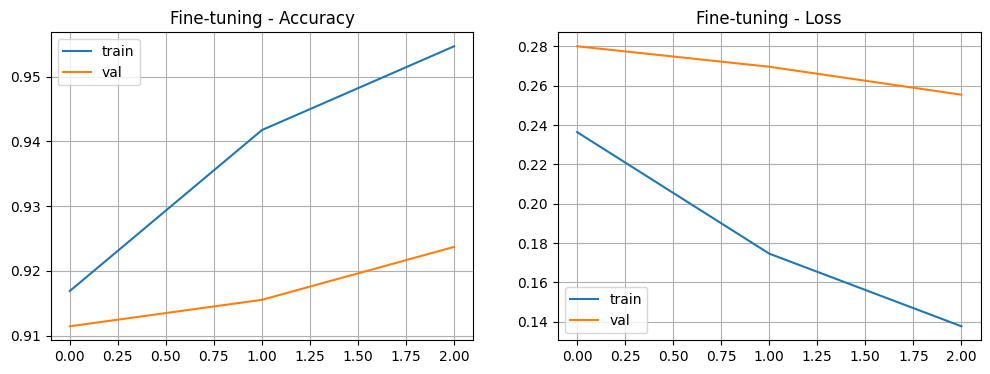

In [16]:
base_model.trainable=True

#Замораживаем ВСЕ слои, кроме последних 30
for layer in base_model.layers[:-30]:
  layer.trainable = False

# Компилируем с ОЧЕНЬ МАЛЕНЬКИМ learning rate (1e-5)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# Дообучаем еще 3 эпохи
history_ft = model.fit(train_ds, validation_data=val_ds, epochs=3 )

# Строим графики
plot_history(history_ft, "Fine-tuning")

**9. Гадаем**

Загрузите картинку с цветком:


Saving tulpain.jpg to tulpain.jpg


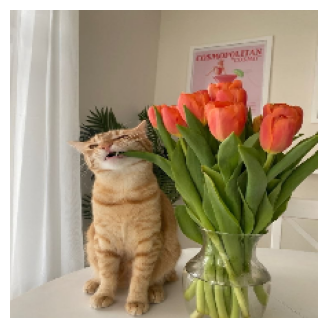


Модель уверена на 90.7%, что это: ROSES

Топ-3 варианта:
  roses: 90.66%
  tulips: 8.72%
  daisy: 0.44%


In [18]:
print("Загрузите картинку с цветком:")
uploaded = files.upload()
fn = list(uploaded.keys())[0]

# Загружаем и показываем
img = tf.keras.utils.load_img(fn, target_size=(224, 224))
plt.figure(figsize=(5, 4))
plt.imshow(img)
plt.axis('off')
plt.show()

# Готовим тензор
x = tf.keras.utils.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

# Предсказываем
preds = model.predict(x, verbose=0)[0]
idx = int(np.argmax(preds))

print(f"\nМодель уверена на {preds[idx]*100:.1f}%, что это: {class_names[idx].upper()}")

print("\nТоп-3 варианта:")
for i in np.argsort(preds)[::-1][:3]:
    print(f"  {class_names[i]}: {preds[i]*100:.2f}%")